# 02 - Baselines (E0 - E2)

- **E0** majority class: always predicts the most common label, shows what no learning gets
- **E1** TF-IDF on words + logistic regression: my main baseline
- **E2** TF-IDF on character n-grams + logistic regression: to see if letter chunks handle the spelling variation better

For E1 and E2 I also try `class_weight="balanced"` because neutral is so rare.
I pick the settings using the dev set only. The test sets are used once, at the end.

In [1]:
import sys

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

sys.path.append("../src")
from evaluate import get_scores, print_report, plot_confusion, log_result

train = pd.read_csv("../data/processed/train.csv")
dev = pd.read_csv("../data/processed/dev.csv")
test_official = pd.read_csv("../data/processed/test_official.csv")
test_clean = pd.read_csv("../data/processed/test_clean.csv")
print(len(train), len(dev), len(test_official), len(test_clean))

4577 996 4154 3228


## E0 - majority class

In [2]:
majority = DummyClassifier(strategy="most_frequent")
majority.fit(train["text"], train["label"])
print("always predicts:", majority.predict(["anything"])[0])
get_scores(dev["label"], majority.predict(dev["text"]))

always predicts: negative


{'accuracy': 0.6506,
 'macro_f1': 0.2628,
 'weighted_f1': 0.5129,
 'f1_negative': 0.7883,
 'f1_neutral': 0.0,
 'f1_positive': 0.0}

About 62% accuracy without learning anything, but macro-F1 is low because neutral and positive get
0. That's why I use macro-F1 as the main metric: accuracy hides that the model ignores whole classes.

## E1 / E2 - TF-IDF + logistic regression

`C` controls regularisation: small C = simpler model (less overfitting), big C = fits the training
data more closely. I try a few values and keep the best on dev.

In [3]:
def make_pipeline(analyzer, ngram_range, C, class_weight=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer=analyzer, ngram_range=ngram_range, sublinear_tf=True, min_df=2)),
        ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=2000)),
    ])


configs = {
    "E1": ("word", (1, 2), None),
    "E1b": ("word", (1, 2), "balanced"),
    "E2": ("char_wb", (2, 5), None),
    "E2b": ("char_wb", (2, 5), "balanced"),
}

tuning = []
best = {}
for exp_id, (analyzer, ngrams, cw) in configs.items():
    for C in [0.3, 1, 3, 10]:
        model = make_pipeline(analyzer, ngrams, C, cw)
        model.fit(train["text"], train["label"])
        scores = get_scores(dev["label"], model.predict(dev["text"]))
        tuning.append({"exp_id": exp_id, "C": C, **scores})
        if exp_id not in best or scores["macro_f1"] > best[exp_id][1]["macro_f1"]:
            best[exp_id] = (C, scores, model)

tuning = pd.DataFrame(tuning)
tuning.pivot(index="C", columns="exp_id", values="macro_f1")

exp_id,E1,E1b,E2,E2b
C,,,,
0.3,0.3393,0.4212,0.3631,0.4408
1.0,0.3847,0.4281,0.4088,0.4426
3.0,0.4023,0.4232,0.4145,0.4414
10.0,0.4118,0.4221,0.4009,0.4388


In [4]:
# best C per experiment on dev
pd.DataFrame({k: {"best C": v[0], **v[1]} for k, v in best.items()}).T

,best C,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
E1,10.0,0.6787,0.4118,0.6575,0.7758,0.0000,0.4596
E1b,1.0,0.6737,0.4281,0.6678,0.7570,0.0000,0.5273
E2,3.0,0.6817,0.4145,0.6608,0.7778,0.0000,0.4658
E2b,1.0,0.6526,0.4426,0.6556,0.7353,0.0625,0.5301


## Final scores (dev + both test sets)

In [5]:
names = {
    "E0": "majority class",
    "E1": "tfidf word 1-2gram + logreg",
    "E1b": "tfidf word 1-2gram + logreg (balanced)",
    "E2": "tfidf char 2-5gram + logreg",
    "E2b": "tfidf char 2-5gram + logreg (balanced)",
}
models = {"E0": majority, **{k: v[2] for k, v in best.items()}}

rows = []
for exp_id, model in models.items():
    note = "" if exp_id == "E0" else f"C={best[exp_id][0]}"
    for split_name, df in [("dev", dev), ("test_official", test_official), ("test_clean", test_clean)]:
        scores = get_scores(df["label"], model.predict(df["text"]))
        log_result(exp_id, names[exp_id], split_name, scores, note)
        rows.append({"exp_id": exp_id, "split": split_name, **scores})

results = pd.DataFrame(rows)
results.pivot(index="exp_id", columns="split", values="macro_f1")

split,dev,test_clean,test_official
exp_id,,,
E0,0.2628,0.2307,0.2393
E1,0.4118,0.3984,0.4438
E1b,0.4281,0.4331,0.4683
E2,0.4145,0.4027,0.4427
E2b,0.4426,0.4269,0.4590


In [6]:
results[results["split"] == "test_clean"].set_index("exp_id")

,split,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
exp_id,,,,,,,
E0,test_clean,0.5291,0.2307,0.3662,0.6921,0.0000,0.0000
E1,test_clean,0.5982,0.3984,0.5403,0.7134,0.0000,0.4817
E1b,test_clean,0.6224,0.4331,0.5761,0.7215,0.0046,0.5731
E2,test_clean,0.6050,0.4027,0.5460,0.7206,0.0000,0.4875
E2b,test_clean,0.6016,0.4269,0.5626,0.6977,0.0176,0.5655


## Looking closer at the best baseline

best on dev: E2b tfidf char 2-5gram + logreg (balanced)


              precision    recall  f1-score   support

    negative      0.656     0.745     0.698      1708
     neutral      0.154     0.009     0.018       429
    positive      0.527     0.610     0.565      1091

    accuracy                          0.602      3228
   macro avg      0.446     0.455     0.427      3228
weighted avg      0.546     0.602     0.563      3228



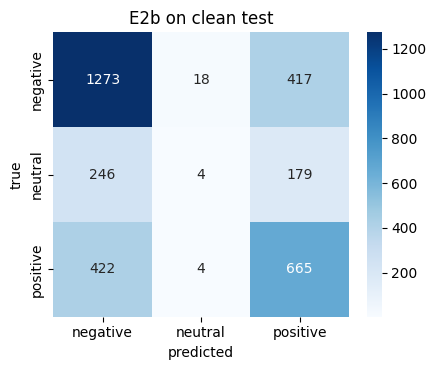

In [7]:
best_id = results[results["split"] == "dev"].set_index("exp_id")["macro_f1"].idxmax()
best_model = models[best_id]
print("best on dev:", best_id, names[best_id])
pred = best_model.predict(test_clean["text"])
print_report(test_clean["label"], pred)
plot_confusion(test_clean["label"], pred, f"{best_id} on clean test", f"confusion_{best_id}_test_clean.png")

In [8]:
# which words push the most towards each class (word model only, easier to read)
word_model = models["E1b"]
vocab = np.array(word_model.named_steps["tfidf"].get_feature_names_out())
clf = word_model.named_steps["clf"]
top_words = {label: vocab[np.argsort(clf.coef_[i])[-15:][::-1]] for i, label in enumerate(clf.classes_)}
pd.DataFrame(top_words)

,negative,neutral,positive
0,wetin,laycon,love
1,say,look,fine
2,use,to,sweet
3,again,sha,you
4,pain,early,your
5,end,at,me sef
6,people,ones,oya
7,are,im,sabi
8,no,dey heavy,song
9,beat,though,marry
